# Quantification et génération FPGA

Un seul notebook pilote désormais la quantification, la simulation arithmétique bit-exacte, les fichiers mémoire et le RTL. Pour changer de plateforme, modifiez uniquement `target` et `architecture` dans la configuration.

In [15]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

# Renseignez ce chemin uniquement si Jupyter est lancé hors du dépôt.
PROJECT_ROOT_OVERRIDE = None  # Exemple : Path('/chemin/vers/RECIPE_MLP_FPGA')

candidates = [PROJECT_ROOT_OVERRIDE] if PROJECT_ROOT_OVERRIDE else []
candidates += [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (path.resolve() for path in candidates if path and (path / 'src' / 'py' / 'fpga_targets.py').is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError(
        'Racine introuvable : renseignez PROJECT_ROOT_OVERRIDE avec le dossier du dépôt.'
    )

source_dir = PROJECT_ROOT / 'src' / 'py'
if str(source_dir) not in sys.path:
    sys.path.insert(0, str(source_dir))

from quantization import (
    TARGET_PROFILES,
    run_quantization,
    validate_quantization_config,
)

## Configuration unique

Choix disponibles :

- `target`: `ultra96` (AXI-Stream, DSP 48 bits) ou `lattice` (UART, DSP 32 bits) ;
- `architecture`: `sequential` ou `pipeline`.

In [ ]:

config = {
    'name': 'fashion_mnist_q16',
    'model_path': 'data/fashion_mnist/mlp_fashion_mnist.pt',
    'dataset_path': 'data/fashion_mnist.npz',
    'output_root': 'data/quantized_data',

    'target': 'nexys_a7',            # ultra96, lattice or nexys_a7
    'architecture': 'sequential',    # sequential or pipeline
    'device': 'cpu',

    'weight_bits': 8,
    'bias_bits': 16,
    'act_bits': 16,
    'dsp_bits': 48,
    'margin_weights': 0.0,
    'margin_acts': 0.0,
    'calibration_mode': 'max',       # max or percentile
    'calibration_percentile': 99.9,
    'activation_negative_slope': 1 / 64,

    'dsp_acc_max_utilization': 0.90,
    'dsp_weight_search_max_steps': 24,

    'lut_addr_bits_min': 3,
    'lut_addr_bits_max_cap': 9,
    'lut_max_words': 1024,
    'lut_auto_window': 2,
    'activation_score_memory_weight': 0.03,

    'test_samples': 100,
    'simulation_samples': None,      # None = toute la base
    'fail_on_overflow': True,
    'generate_report': True,
    'generate_rtl': True,
}

config = validate_quantization_config(config)
TARGET_PROFILES[config['target']]


TargetProfile(name='nexys_a7', transport='uart', dsp_bits=48, toolchain='vivado', device='xc7a100tcsg324-1', executables=('vivado',))

## Exécution complète

Cette cellule calibre les échelles, protège le DSP, sélectionne les LUT, exporte les mémoires, simule le datapath de la carte et génère le RTL correspondant.

In [18]:
import importlib
import inspect

import analysis
import quantization

# Recharger analysis.py
importlib.invalidate_caches()
importlib.reload(analysis)

# Recharger quantization.py pour récupérer la nouvelle fonction
importlib.reload(quantization)

# Actualiser la fonction utilisée dans le notebook
from quantization import run_quantization

# Vérifier le code réellement utilisé
print("Fonction actualisée :")
print(inspect.getsource(analysis.build_model_info_lines))

print(
    "Bonne version utilisée :",
    "y_rad.shape[1]" not in inspect.getsource(
        analysis.build_model_info_lines
    )
)

Fonction actualisée :
def build_model_info_lines(
    *,
    model,
    config: dict[str, Any],
    activation_plan: list[dict[str, Any]],
    activation_best_df: pd.DataFrame | None,
    x,
    y,
    qcfg: Any,
) -> list[str]:
    best_activation_map = _build_best_activation_map(activation_best_df)

    activation_lines = []
    for spec in activation_plan:
        layer_name = f"layer_{spec['layer_index']}"
        best_meta = best_activation_map.get(layer_name, {})
        if best_meta:
            if best_meta.get("implementation") == "paper_fit":
                activation_lines.append(
                    f"{layer_name}: {spec['name']} | impl={best_meta['implementation']} | N_best={int(best_meta['addr_bits'])}"
                )
            else:
                activation_lines.append(f"{layer_name}: {spec['name']} | impl={best_meta['implementation']}")
        else:
            activation_lines.append(f"{layer_name}: {spec['name']}")

    return [
        f"Architecture : {tup


BASIC QUANTIZATION
Model path       : C:\Users\adams\Documents\MLP_HLS-main\data\fashion_mnist\mlp_fashion_mnist.pt
Dataset path     : C:\Users\adams\Documents\MLP_HLS-main\data\fashion_mnist.npz
Output directory : C:\Users\adams\Documents\MLP_HLS-main\data\quantized_data\fashion_mnist_q16\nexys_a7\sequential
FPGA export mode : sequential
ACT_W / DSP_PW   : 16 / 48
Number of layers : 3


,layer,is_output,w_shape,input_exp,weight_exp,bias_exp,preact_exp,act_exp,output_exp,activation
0,layer_0,False,"(64, 784)",14,14,15,9.0,10.0,NaN,leaky_relu
1,layer_1,False,"(32, 64)",10,14,15,9.0,10.0,NaN,leaky_relu
2,layer_2,True,"(10, 32)",10,14,16,NaN,NaN,7.0,-



DSP-AWARE WEIGHT SCALE OPTIMIZATION -- FLOAT CALIBRATION
DSP_PW                  : 48 bits
Allowed utilization     : 90.0%
Calibration source      : original FLOAT tensors, independently per layer
Scale modified          : SW only, independently for each layer
Stored weights          : re-quantized from W_float at each SW_selected
Report CSV              : C:\Users\adams\Documents\MLP_HLS-main\data\quantized_data\fashion_mnist_q16\nexys_a7\sequential\dsp_accumulator_report.csv


,layer,is_output,calibration_domain,sx,sb,sw_initial,sw_selected,sw_bits_lost,s_acc_selected,dsp_bits,...,dsp_safe_real_min,dsp_safe_real_max,dsp_utilization_%,safe_window_utilization_%,worst_value_float,worst_sample,worst_neuron,worst_mac_index,worst_sign,candidate_attempts
0,layer_0,False,float,14,15,14,14,0,28,48,...,-471859.2,471859.2,0.007983,0.008870,-41.853388,16490,54,384,negative,1
1,layer_1,False,float,10,15,14,14,0,24,48,...,-7549747.2,7549747.2,0.000424,0.000471,-35.548403,36196,17,62,negative,1
2,layer_2,True,float,10,16,14,14,0,24,48,...,-7549747.2,7549747.2,0.001535,0.001706,-128.804463,21371,1,31,negative,1


,layer_name,activation_name,implementation,addr_bits,input_exp,output_exp,mae,max_abs_err,mae_lsb_out,max_abs_err_lsb_out,...,mae_normalized,memory_bits_normalized,score,touch_last_segment,touch_count,touch_ratio,headroom_q,max_pre_q,max_safe_q,is_best
0,layer_0,leaky_relu,analytic_int,None,9,10,0.000782,0.001938,0.801546,2.0,...,NaN,NaN,NaN,False,0,0.0,NaN,11130,NaN,True
1,layer_1,leaky_relu,analytic_int,None,9,10,0.000720,0.001938,0.737636,2.0,...,NaN,NaN,NaN,False,0,0.0,NaN,13824,NaN,True



FINAL EXPORT OF CONCATENATED .MEM ARTIFACTS
Export directory      : C:\Users\adams\Documents\MLP_HLS-main\data\quantized_data\fashion_mnist_q16\nexys_a7\sequential
Verilog header      : C:\Users\adams\Documents\MLP_HLS-main\data\quantized_data\fashion_mnist_q16\nexys_a7\sequential\scales.vh
.mem files       :
- weights             : C:\Users\adams\Documents\MLP_HLS-main\data\quantized_data\fashion_mnist_q16\nexys_a7\sequential\weight_all.mem (52544 words)
- biases             : C:\Users\adams\Documents\MLP_HLS-main\data\quantized_data\fashion_mnist_q16\nexys_a7\sequential\bias_all.mem (106 words)
- LUT activations   : C:\Users\adams\Documents\MLP_HLS-main\data\quantized_data\fashion_mnist_q16\nexys_a7\sequential\act_all.mem (0 words)
Layout debug        : C:\Users\adams\Documents\MLP_HLS-main\data\quantized_data\fashion_mnist_q16\nexys_a7\sequential\mem_layout.json

Weight/bias layout :
- layer_0 | W offset=0 len=50176 shape=(64, 784) | B offset=0 len=64
- layer_1 | W offset=50176 len

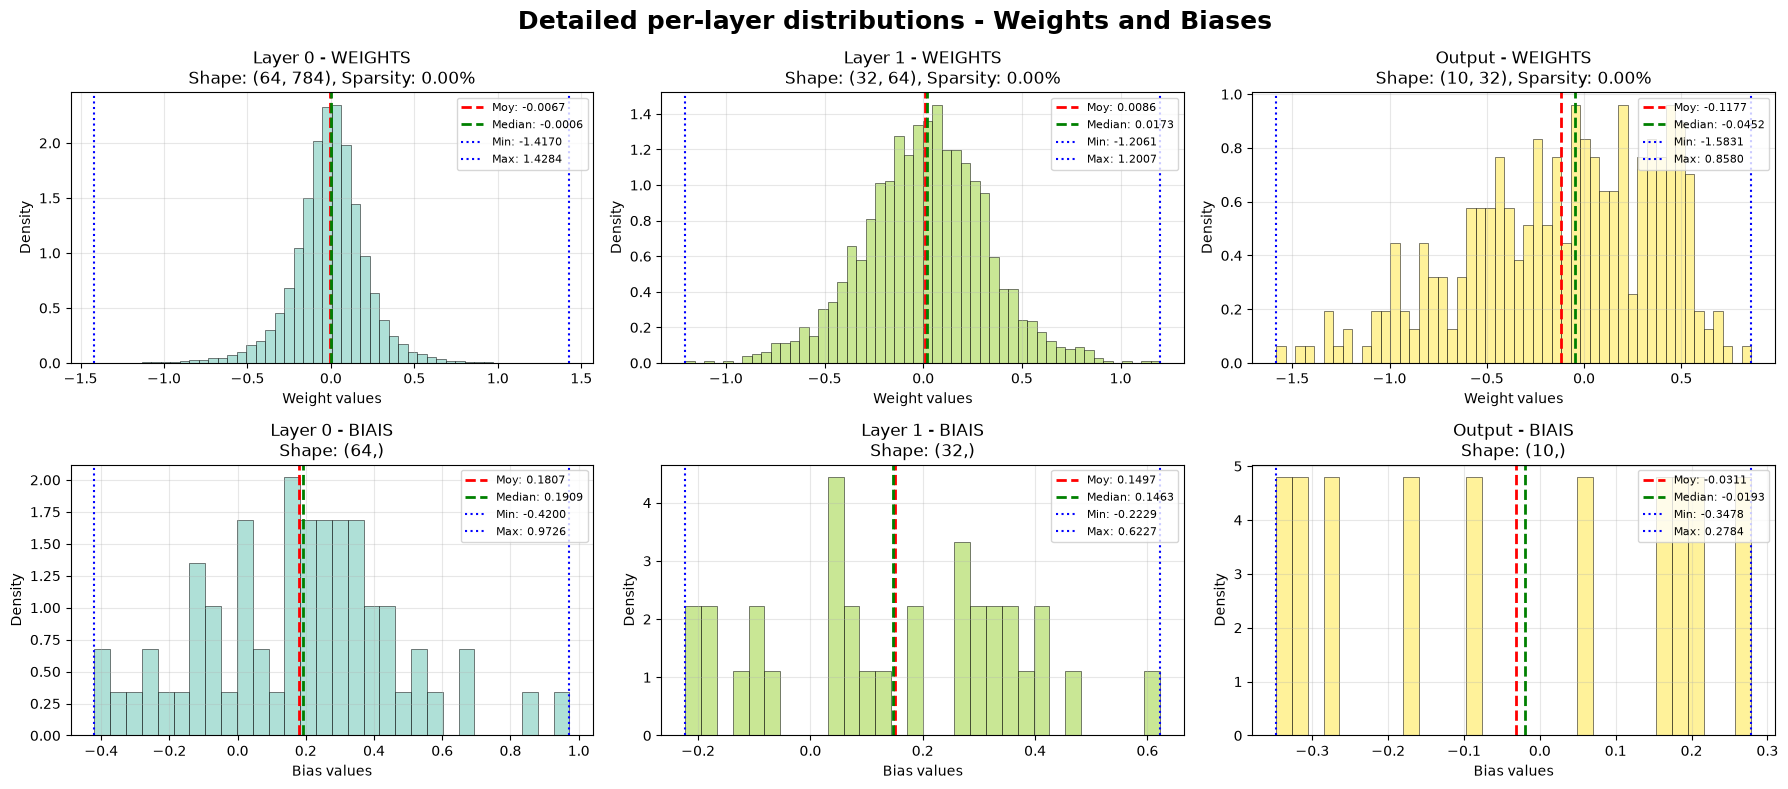

✅ Per-layer distribution plots generated


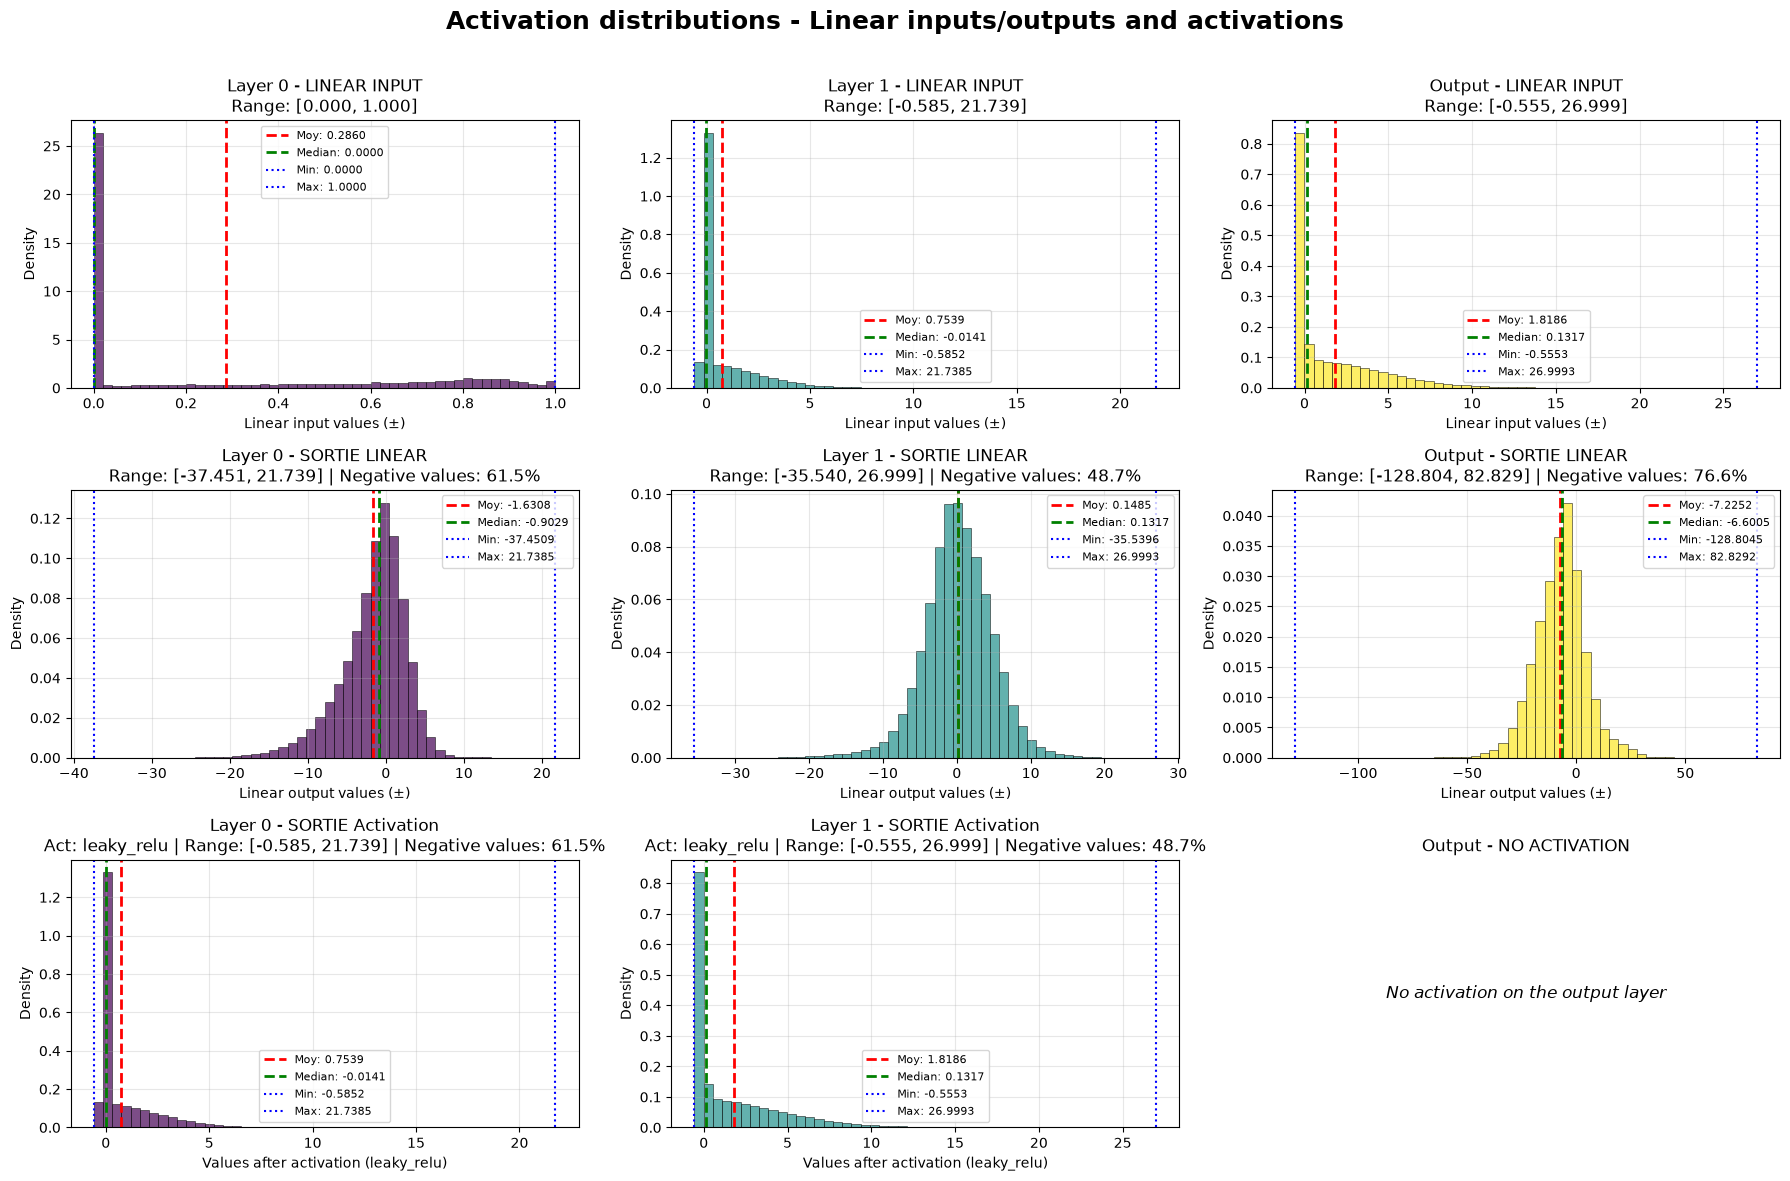

✅ Activation distribution plots generated


,tensor,layer,kind,activation,implementation,selected_N,shift_exponent,scale_factor,bits,float32_min,float32_max,int_min,int_max,utilisation_sym_%
0,input,-,input,-,-,-,14,16384,16,0.000000,1.000000,0,16384,50.0%
1,layer_0_weights,layer_0,weights,-,-,-,14,16384,16,-1.417008,1.428411,-23216,23403,71.4%
2,layer_0_bias,layer_0,bias,-,-,-,15,32768,16,-0.419986,0.972603,-13762,31870,97.3%
3,layer_0_preact,layer_0,preact,leaky_relu,analytic_int,-,9,512,16,-37.450912,21.738537,-19175,11130,58.5%
4,layer_0_act,layer_0,act,leaky_relu,analytic_int,-,10,1024,16,-0.585171,21.738537,-599,22260,67.9%
5,layer_1_weights,layer_1,weights,-,-,-,14,16384,16,-1.206110,1.200693,-19761,19672,60.3%
6,layer_1_bias,layer_1,bias,-,-,-,15,32768,16,-0.222863,0.622719,-7303,20405,62.3%
7,layer_1_preact,layer_1,preact,leaky_relu,analytic_int,-,9,512,16,-35.539608,26.999302,-18196,13824,55.5%
8,layer_1_act,layer_1,act,leaky_relu,analytic_int,-,10,1024,16,-0.555306,26.999302,-569,27647,84.4%
9,layer_2_weights,layer_2,weights,-,-,-,14,16384,16,-1.583069,0.858016,-25937,14058,79.2%


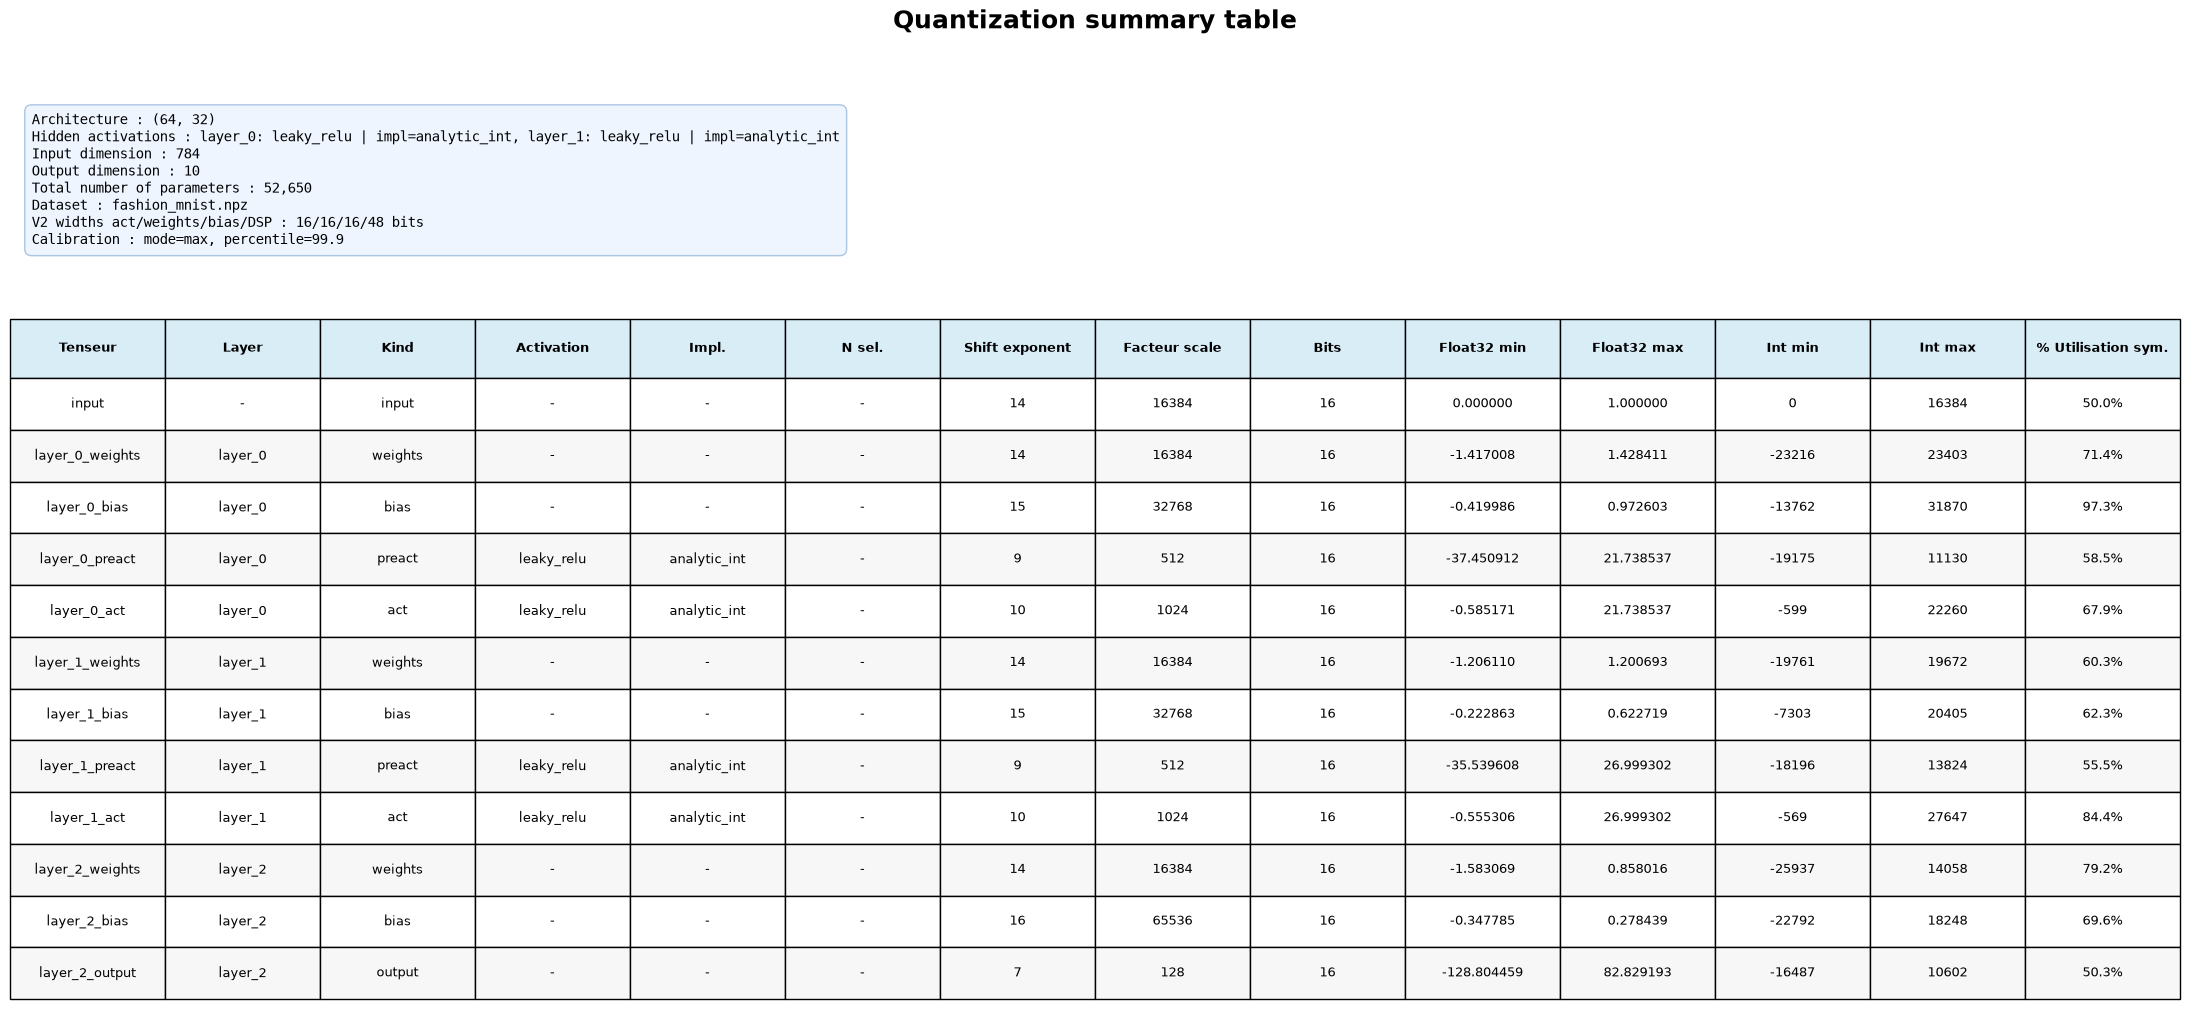

✅ Quantization summary table generated
✅ PDF exported : C:\Users\adams\Documents\MLP_HLS-main\data\quantized_data\fashion_mnist_q16\nexys_a7\sequential\distribution_analysis_report.pdf

QUANTIZATION COMPLETE
Target / mode : nexys_a7 / sequential
DSP / transport: 48 bits / uart
Output          : C:\Users\adams\Documents\MLP_HLS-main\data\quantized_data\fashion_mnist_q16\nexys_a7\sequential
FPGA overflows  : 0
Float accuracy : 93.73%
FPGA accuracy  : 93.72%
Class agreement: 99.98%


In [20]:
run = run_quantization(config, project_root=PROJECT_ROOT)

## Résultats de la simulation FPGA

In [21]:
pd.Series(run.simulation_summary, name='value').to_frame()

,value
samples,60000
target,nexys_a7
architecture,sequential
transport,uart
dsp_bits,48
input_exp,14
output_exp,7
overflow_count,0
float_accuracy,0.937317
board_accuracy,0.937183


In [22]:
run.simulation_report

,layer,layer_index,input_exp,weight_exp,bias_exp,accumulator_exp,accumulator_min,accumulator_max,bias_wrap_count,product_wrap_count,accumulator_wrap_count,preactivation_exp,preactivation_shift_wrap_count,activation_shift_wrap_count,output_narrowing_count,output_exp,output_min,output_max,overflow_count
0,layer_0,0,14,14,15,28,-10053069818,5835334332,0,0,0,9.0,0.0,0,0,10,-600,22260,0
1,layer_1,1,10,14,15,24,-596183602,452851430,0,0,0,9.0,0.0,0,0,10,-570,27638,0
2,layer_2,2,10,14,16,24,-2160808402,1389436098,0,0,0,NaN,NaN,0,0,7,-16486,10600,0


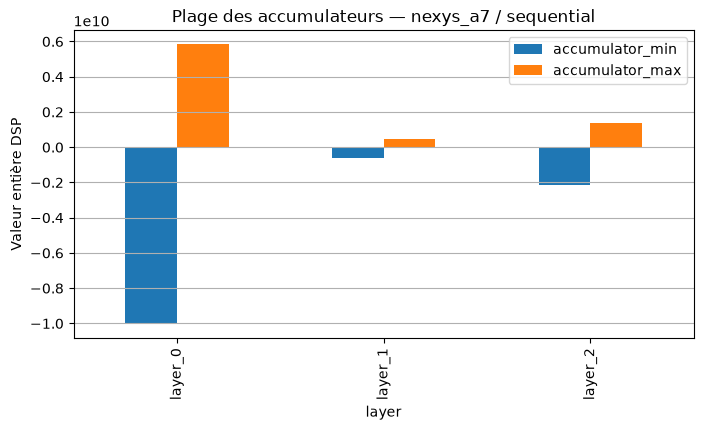

In [23]:
fig, ax = plt.subplots(figsize=(8, 4))
run.simulation_report.plot(
    x='layer',
    y=['accumulator_min', 'accumulator_max'],
    kind='bar',
    ax=ax,
)
ax.set_title(f"Plage des accumulateurs — {config['target']} / {config['architecture']}")
ax.set_ylabel('Valeur entière DSP')
ax.grid(True, axis='y')
plt.show()

## Artefacts

Le manifeste ci-dessous référence la configuration, les mémoires, le dataset quantifié, les vecteurs de testbench, le rapport de simulation et le RTL généré.

In [24]:
print(f'Manifeste : {run.manifest_path}')
print(f'Dataset quantifié : {run.dataset_path}')
if run.rtl_project:
    print(f"RTL : {run.rtl_project['generated_rtl_dir']}")

Manifeste : C:\Users\adams\Documents\MLP_HLS-main\data\quantized_data\fashion_mnist_q16\nexys_a7\sequential\quantization_manifest.json
Dataset quantifié : C:\Users\adams\Documents\MLP_HLS-main\data\quantized_data\fashion_mnist_q16\nexys_a7\sequential\fashion_mnist_quantized.npz
RTL : C:\Users\adams\Documents\MLP_HLS-main\src\rtl\generated\src_nexys_sequential
